# Reto AgroCebada FIRA 2026
## Libreta 01 · Calidad y Contexto Agronómico

> *"Antes de predecir el rendimiento, necesitamos entender qué miden realmente nuestros satélites, qué limitaciones tiene cada sensor y cómo se distribuyen las parcelas en el territorio."*

### Sección del Reporte que alimenta esta libreta
| Sección del Reporte | Contenido generado aquí |
|---|---|
| **Introducción** | Descripción del dataset, ventana temporal y distribución geográfica |
| **Justificación** | Diagnóstico de calidad de sensores y necesidad de fusión satelital |

### Objetivos de esta libreta
1. Cargar y validar la estructura completa del `DataSet.zip` entregado por FIRA.
2. Analizar la distribución espacial de las 197 parcelas (desarrollo vs predicción).
3. Diagnosticar la calidad de las observaciones satelitales (Sentinel-2, Landsat, Planet).
4. Generar el **mapa de calor de cobertura mensual** que demuestra por qué ciertos meses críticos requieren fusión de satélites.

### Alcance temporal
Ciclo agrícola **abril–octubre de 2025**. Este análisis es retrospectivo sobre el ciclo completo, no constituye un pronóstico anticipado antes de cosecha.

In [ ]:
# ============================================================
# CONFIGURACIÓN MAESTRA - Entorno
# ============================================================
import os
from pathlib import Path

EN_COLAB = True  # <-- Cambiar a False si el evaluador lo corre en su PC local (GitHub)

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Reto_AgroCebada_2026')
else:
    # Usa el directorio actual (la raíz del repositorio clonado de GitHub)
    BASE = Path(os.getcwd())

CARPETAS = {
    'raw':           BASE / 'data' / 'raw',
    '01_calidad':    BASE / 'data' / '01_calidad',
    '02_fenologia':  BASE / 'data' / '02_fenologia',
    '03_validacion': BASE / 'data' / '03_validacion',
    '04_shap':       BASE / 'data' / '04_shap',
    '05_final':      BASE / 'data' / '05_final',
    'models':        BASE / 'models',
    'artifacts':     BASE / 'artifacts', # <-- Aquí irán los archivos del Dashboard
    'reports':       BASE / 'reports',
}

for carpeta in CARPETAS.values():
    carpeta.mkdir(parents=True, exist_ok=True)

# --- Funciones helper ---
def guardar_csv(df, nombre, carpeta='raw'):
    """Guarda un DataFrame en la carpeta indicada."""
    ruta = CARPETAS[carpeta] / nombre
    df.to_csv(ruta, index=False, encoding='utf-8-sig')
    print(f"✅ Guardado: {ruta}")
    return ruta

def cargar_csv(nombre, carpeta='raw', **kwargs):
    """Carga un CSV desde la carpeta indicada."""
    ruta = CARPETAS[carpeta] / nombre
    assert ruta.exists(), f"❌ No existe: {ruta}"
    df = pd.read_csv(ruta, **kwargs)
    print(f"📂 Cargado: {nombre} ({df.shape[0]} filas × {df.shape[1]} cols)")
    return df

def guardar_json(obj, nombre, carpeta='raw'):
    ruta = CARPETAS[carpeta] / nombre
    with open(ruta, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)
    print(f"✅ Guardado: {ruta}")
    return ruta

def cargar_json(nombre, carpeta='raw'):
    ruta = CARPETAS[carpeta] / nombre
    assert ruta.exists(), f"❌ No existe: {ruta}"
    with open(ruta, 'r', encoding='utf-8') as f:
        return json.load(f)

def guardar_figura(fig, nombre, carpeta='reports'):
    ruta = CARPETAS[carpeta] / nombre
    fig.savefig(ruta, dpi=200, bbox_inches='tight')
    print(f"✅ Gráfico guardado: {ruta}")
    return ruta

def guardar_modelo(modelo, nombre):
    import joblib
    ruta = CARPETAS['models'] / nombre
    joblib.dump(modelo, ruta)
    print(f"✅ Modelo guardado: {ruta}")
    return ruta

def cargar_modelo(nombre):
    import joblib
    ruta = CARPETAS['models'] / nombre
    assert ruta.exists(), f"❌ No existe: {ruta}"
    return joblib.load(ruta)

def listar_archivos(carpeta='raw'):
    """Lista los archivos disponibles en una carpeta."""
    ruta = CARPETAS[carpeta]
    archivos = sorted(ruta.iterdir()) if ruta.exists() else []
    if not archivos:
        print(f"📁 Carpeta '{carpeta}' vacía")
    else:
        print(f"📁 Carpeta '{carpeta}': {len(archivos)} archivos")
        for a in archivos:
            tamaño = a.stat().st_size
            unidad = 'MB' if tamaño > 1e6 else 'KB' if tamaño > 1e3 else 'B'
            valor = tamaño / 1e6 if tamaño > 1e6 else tamaño / 1e3 if tamaño > 1e3 else tamaño
            print(f"   • {a.name} ({valor:.1f} {unidad})")
    return archivos

def sha256(ruta):
    """Calcula hash SHA-256 de un archivo."""
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b''):
            h.update(chunk)
    return h.hexdigest()

print("=" * 60)
print("🗂️  ESTRUCTURA DE DRIVE LISTA")
print("=" * 60)
for nombre, ruta in CARPETAS.items():
    print(f"   {nombre:>15}: {ruta}")
print("\nFunciones disponibles: guardar_csv, cargar_csv, guardar_json,")
print("cargar_json, guardar_figura, guardar_modelo, cargar_modelo,")
print("listar_archivos, sha256")

Mounted at /content/drive
🗂️  ESTRUCTURA DE DRIVE LISTA
               raw: /content/drive/MyDrive/Reto_AgroCebada_2026/data/raw
        01_calidad: /content/drive/MyDrive/Reto_AgroCebada_2026/data/01_calidad
      02_fenologia: /content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia
     03_validacion: /content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion
           04_shap: /content/drive/MyDrive/Reto_AgroCebada_2026/data/04_shap
          05_final: /content/drive/MyDrive/Reto_AgroCebada_2026/data/05_final
            models: /content/drive/MyDrive/Reto_AgroCebada_2026/models
         artifacts: /content/drive/MyDrive/Reto_AgroCebada_2026/artifacts
           reports: /content/drive/MyDrive/Reto_AgroCebada_2026/reports

Funciones disponibles: guardar_csv, cargar_csv, guardar_json,
cargar_json, guardar_figura, guardar_modelo, cargar_modelo,
listar_archivos, sha256


In [ ]:
# ============================================================
# SUBIR DATASET ORIGINAL A DRIVE (solo la primera vez)
# ============================================================
from google.colab import files
import zipfile, shutil

print("Selecciona el archivo DataSet.zip:")
subidos = files.upload()

for nombre, contenido in subidos.items():
    destino = CARPETAS['raw'] / nombre
    with open(destino, 'wb') as f:
        f.write(contenido)
    print(f"✅ Subido a Drive: {destino}")

    # Extraer automáticamente
    if nombre.lower().endswith('.zip'):
        carpeta_ext = CARPETAS['raw'] / 'extraido'
        carpeta_ext.mkdir(exist_ok=True)
        with zipfile.ZipFile(destino, 'r') as z:
            z.extractall(carpeta_ext)
        print(f"📦 Extraído en: {carpeta_ext}")
        for f in sorted(carpeta_ext.iterdir()):
            print(f"   • {f.name}")

Selecciona el archivo DataSet.zip:


Saving DataSet.zip to DataSet.zip
✅ Subido a Drive: /content/drive/MyDrive/Reto_AgroCebada_2026/data/raw/DataSet.zip
📦 Extraído en: /content/drive/MyDrive/Reto_AgroCebada_2026/data/raw/extraido
   • DATASET_RETO_AGRO_2026


In [ ]:
# ============================================================
# CONFIGURACIÓN GLOBAL DEL PROYECTO
# ============================================================
!pip install -q geopandas shapely pyproj pyshp rasterio rasterstats optuna shap

import os
import zipfile
import json
import hashlib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from io import BytesIO
import warnings
warnings.filterwarnings('ignore')

# Estilo visual para las gráficas del reporte
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Directorio de trabajo y salidas
SALIDA = CARPETAS['01_calidad']   # persiste en Drive (antes: disco temporal de Colab)
SALIDA.mkdir(parents=True, exist_ok=True)

# Carpeta donde se extrajo DataSet.zip (la usan las celdas de carga de esta libreta)
CARPETA_DATOS = CARPETAS['raw'] / 'extraido'

# Parámetros del proyecto
INICIO = '2025-04-01'
FIN = '2025-10-31'
MESES = [f'2025-{m:02d}' for m in range(4, 11)]
NOMBRES_MESES = ['Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre']

print("✅ Configuración completada")
print(f"   Ventana temporal: {INICIO} a {FIN}")
print(f"   Directorio de salida: {SALIDA}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.4 MB/s eta 0:00:00
✅ Configuración completada
   Ventana temporal: 2025-04-01 a 2025-10-31
   Directorio de salida: /content/drive/MyDrive/Reto_AgroCebada_2026/data/01_calidad


In [ ]:
# ============================================================
# CARGA DE DATOS DESDE DRIVE
# ============================================================
import zipfile
import geopandas as gpd

# Ruta raíz de extracción en Drive
RAW = CARPETAS['raw'] / 'extraido' / 'DATASET_RETO_AGRO_2026'

# Tabla Maestra
df_master = pd.read_csv(RAW / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv')
df_master['ID_POLIGONO'] = df_master['ID_POLIGONO'].str.strip()
columnas_vacias = [c for c in df_master.columns if c.startswith('Unnamed:') and df_master[c].isna().all()]
if columnas_vacias:
    df_master = df_master.drop(columns=columnas_vacias)

# Dataset PRO
df_pro = pd.read_csv(RAW / 'Conjunto_datos_PRO_AgroCebada.csv', dtype={'ID_POLIGONO': str})
df_pro['ID_POLIGONO'] = df_pro['ID_POLIGONO'].str.strip()

# Dataset Básico
df_basico = pd.read_csv(RAW / 'Conjunto_datos_BASICO_AgroCebada2026.csv', dtype={'ID_POLIGONO': str})
df_basico['ID_POLIGONO'] = df_basico['ID_POLIGONO'].str.strip()

# Shapefile - Extraer si está comprimido
zip_shp = RAW / 'Parcelas_Reto_AGC_CONJUNTO_70_30.zip'
carpeta_shp_ext = RAW / 'parcelas_temp'
if zip_shp.exists() and not carpeta_shp_ext.exists():
    carpeta_shp_ext.mkdir(exist_ok=True)
    with zipfile.ZipFile(zip_shp, 'r') as z:
        z.extractall(carpeta_shp_ext)

# Buscar el archivo .shp
shp_files = list(carpeta_shp_ext.glob('*.shp')) if carpeta_shp_ext.exists() else []
if not shp_files:
    # Intentar buscar en el directorio raíz por si acaso
    shp_files = list(RAW.glob('*.shp'))

assert len(shp_files) == 1, f"Se esperaba 1 .shp, se encontraron {len(shp_files)}"
gdf_parcelas = gpd.read_file(shp_files[0])

# Clima y topografía (se genera en la Libreta 02; aquí es opcional)
ruta_clima = CARPETAS['raw'] / 'datos_clima_topografia.csv'
if ruta_clima.exists():
    df_clima = pd.read_csv(ruta_clima)
    print(f"✅ Clima cargado desde Drive ({df_clima.shape[1]-1} variables)")
else:
    print("⚠️ datos_clima_topografia.csv no encontrado; se genera en la Libreta 02.")

print(f"✅ Maestro: {len(df_master)} parcelas")
print(f"✅ PRO: {len(df_pro)} capturas")
print(f"✅ Básico: {len(df_basico)} capturas")
print(f"✅ Shapefile: {len(gdf_parcelas)} geometrías")

⚠️ datos_clima_topografia.csv no encontrado; se genera en la Libreta 02.
✅ Maestro: 197 parcelas
✅ PRO: 47804 capturas
✅ Básico: 107666 capturas
✅ Shapefile: 197 geometrías


In [ ]:
# ============================================================
# 2. CARGA Y VALIDACIÓN DE LAS TABLAS PRINCIPALES
# ============================================================

# --- Tabla Maestra (ID, Área, Rendimiento, Conjunto) ---
ruta_maestro = CARPETA_DATOS / 'DATASET_RETO_AGRO_2026' / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv'
df_maestro = pd.read_csv(ruta_maestro)

# Limpieza
df_maestro['ID_POLIGONO'] = df_maestro['ID_POLIGONO'].astype(str).str.strip()
# Eliminar columnas completamente vacías
columnas_vacias = [c for c in df_maestro.columns if c.startswith('Unnamed:') and df_maestro[c].isna().all()]
if columnas_vacias:
    df_maestro = df_maestro.drop(columns=columnas_vacias)
    print(f"   Columnas vacías eliminadas: {columnas_vacias}")

# Validaciones
assert len(df_maestro) == 197, f'Se esperaban 197 parcelas, se encontraron {len(df_maestro)}'
assert df_maestro['ID_POLIGONO'].is_unique, 'Hay IDs duplicados'
assert set(df_maestro['CONJUNTO'].unique()) == {'ENTRENAMIENTO', 'PREDICCION'}

# Separación del reto
df_entrenamiento = df_maestro[df_maestro['CONJUNTO'] == 'ENTRENAMIENTO'].copy()
df_prediccion = df_maestro[df_maestro['CONJUNTO'] == 'PREDICCION'].copy()

print("=" * 60)
print("TABLA MAESTRA DE PARCELAS")
print("=" * 60)
print(f"Total de parcelas:       {len(df_maestro)}")
print(f"Entrenamiento (con y):   {len(df_entrenamiento)} ({len(df_entrenamiento)/len(df_maestro)*100:.1f}%)")
print(f"Predicción (sin y):      {len(df_prediccion)} ({len(df_prediccion)/len(df_maestro)*100:.1f}%)")
print(f"\nÁrea (hectáreas):")
print(f"   Media: {df_maestro['AREA_HA'].mean():.2f} ha")
print(f"   Mediana: {df_maestro['AREA_HA'].median():.2f} ha")
print(f"   Mínimo: {df_maestro['AREA_HA'].min():.2f} ha")
print(f"   Máximo: {df_maestro['AREA_HA'].max():.2f} ha")
print(f"\nRendimiento (t/ha) - solo entrenamiento:")
print(f"   Media: {df_entrenamiento['RENDIMIENTO_T_HA'].mean():.2f} t/ha")
print(f"   Mediana: {df_entrenamiento['RENDIMIENTO_T_HA'].median():.2f} t/ha")
print(f"   Desv. Estándar: {df_entrenamiento['RENDIMIENTO_T_HA'].std():.2f} t/ha")
print(f"   Mínimo: {df_entrenamiento['RENDIMIENTO_T_HA'].min():.2f} t/ha")
print(f"   Máximo: {df_entrenamiento['RENDIMIENTO_T_HA'].max():.2f} t/ha")

# Verificar que predicción no tenga rendimiento
assert df_prediccion['RENDIMIENTO_T_HA'].isna().all(), 'Las parcelas de predicción NO deben tener rendimiento'
print("\n✅ Validación: Las 59 parcelas de predicción NO tienen rendimiento conocido")

   Columnas vacías eliminadas: ['Unnamed: 4']
TABLA MAESTRA DE PARCELAS
Total de parcelas:       197
Entrenamiento (con y):   138 (70.1%)
Predicción (sin y):      59 (29.9%)

Área (hectáreas):
   Media: 6.60 ha
   Mediana: 5.46 ha
   Mínimo: 0.35 ha
   Máximo: 64.30 ha

Rendimiento (t/ha) - solo entrenamiento:
   Media: 3.96 t/ha
   Mediana: 4.34 t/ha
   Desv. Estándar: 0.85 t/ha
   Mínimo: 2.00 t/ha
   Máximo: 5.59 t/ha

✅ Validación: Las 59 parcelas de predicción NO tienen rendimiento conocido


In [ ]:
# ============================================================
# 3. CARGA DE LA CAPA ESPACIAL (SHAPEFILE)
# ============================================================

# Extraer el ZIP de parcelas si está contenido dentro del DataSet
archivo_parcelas_zip = CARPETA_DATOS / 'DATASET_RETO_AGRO_2026' / 'Parcelas_Reto_AGC_CONJUNTO_70_30.zip'
CARPETA_PARCELAS = CARPETA_DATOS / 'parcelas'
CARPETA_PARCELAS.mkdir(exist_ok=True)

if archivo_parcelas_zip.exists():
    with zipfile.ZipFile(archivo_parcelas_zip, 'r') as z:
        z.extractall(CARPETA_PARCELAS)
    print(f"✅ ZIP de parcelas extraído")

# Buscar el archivo .shp
archivos_shp = list(CARPETA_PARCELAS.glob('*.shp'))
assert len(archivos_shp) == 1, f'Se esperaba un archivo .shp, se encontraron {len(archivos_shp)}'
ruta_shp = archivos_shp[0]

# Cargar el GeoDataFrame
gdf_parcelas = gpd.read_file(ruta_shp)

# Normalizar el nombre de la columna ID
columnas_id = [c for c in gdf_parcelas.columns if 'ID_POL' in c.upper()]
if columnas_id:
    col_id_shape = columnas_id[0]
else:
    col_id_shape = [c for c in gdf_parcelas.columns if c.lower() != 'geometry'][0]

gdf_parcelas = gdf_parcelas.rename(columns={col_id_shape: 'ID_POLIGONO'})
gdf_parcelas['ID_POLIGONO'] = gdf_parcelas['ID_POLIGONO'].astype(str).str.strip()

# Verificar el sistema de coordenadas
print("=" * 60)
print("CAPA ESPACIAL DE PARCELAS")
print("=" * 60)
print(f"Archivo: {ruta_shp.name}")
print(f"Sistema de Coordenadas: {gdf_parcelas.crs}")
print(f"Número de parcelas: {len(gdf_parcelas)}")
print(f"Columnas de atributos: {list(gdf_parcelas.columns)}")

# Extraer coordenadas del centroide
if gdf_parcelas.crs is None:
    print("⚠️  Sin CRS definido, asumiendo WGS84")
    gdf_parcelas = gdf_parcelas.set_crs('EPSG:4326')

gdf_wgs84 = gdf_parcelas.to_crs(epsg=4326)
gdf_parcelas['longitud'] = gdf_wgs84.geometry.centroid.x
gdf_parcelas['latitud'] = gdf_wgs84.geometry.centroid.y

# Calcular área en hectáreas desde la geometría (para comparar con la tabla)
gdf_metrico = gdf_parcelas.to_crs(epsg=6372)  # México ITRF2008 LCC
gdf_parcelas['area_ha_geometria'] = gdf_metrico.geometry.area / 10000

print(f"\nCoordenadas de los centroides:")
print(f"   Latitud: {gdf_parcelas['latitud'].min():.4f} a {gdf_parcelas['latitud'].max():.4f}")
print(f"   Longitud: {gdf_parcelas['longitud'].min():.4f} a {gdf_parcelas['longitud'].max():.4f}")

✅ ZIP de parcelas extraído
CAPA ESPACIAL DE PARCELAS
Archivo: Parcelas_Reto_AGC_CONJUNTO.shp
Sistema de Coordenadas: EPSG:4326
Número de parcelas: 197
Columnas de atributos: ['Cultivo', 'ID_POLIGONO', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO', 'geometry']

Coordenadas de los centroides:
   Latitud: 19.5257 a 19.9814
   Longitud: -98.6115 a -98.2002


In [ ]:
# ============================================================
# 4. DISTRIBUCIÓN GEOGRÁFICA: ESTADO Y CONJUNTO
# ============================================================

# Fusionar con la tabla maestra
df_geo = df_maestro.merge(
    gdf_parcelas[['ID_POLIGONO', 'Estado', 'Municipio', 'latitud', 'longitud', 'area_ha_geometria']],
    on='ID_POLIGONO',
    how='left'
)

print("=" * 60)
print("DISTRIBUCIÓN POR ESTADO")
print("=" * 60)
tabla_estado = pd.crosstab(df_geo['Estado'], df_geo['CONJUNTO'], margins=True)
print(tabla_estado)

print("\n" + "=" * 60)
print("DISTRIBUCIÓN POR MUNICIPIO")
print("=" * 60)
tabla_municipio = pd.crosstab([df_geo['Estado'], df_geo['Municipio']], df_geo['CONJUNTO'], margins=True)
print(tabla_municipio)

# Verificar que la geometría coincide con la tabla
comparacion_area = df_geo[['AREA_HA', 'area_ha_geometria']].dropna()
correlacion_area = comparacion_area['AREA_HA'].corr(comparacion_area['area_ha_geometria'])
diferencia_relativa = ((comparacion_area['AREA_HA'] - comparacion_area['area_ha_geometria']).abs() / comparacion_area['AREA_HA']).mean()

print(f"\n🔍 Verificación de áreas:")
print(f"   Correlación entre tabla y geometría: {correlacion_area:.4f}")
print(f"   Diferencia relativa media: {diferencia_relativa*100:.2f}%")
if correlacion_area > 0.99:
    print("   ✅ Las áreas coinciden entre la tabla y la geometría")
else:
    print("   ⚠️  Discrepancia en las áreas, revisar")

DISTRIBUCIÓN POR ESTADO
CONJUNTO  ENTRENAMIENTO  PREDICCION  All
Estado                                  
Hidalgo              36          15   51
Puebla               71          29  100
Tlaxcala             31          15   46
All                 138          59  197

DISTRIBUCIÓN POR MUNICIPIO
CONJUNTO                                ENTRENAMIENTO  PREDICCION  All
Estado   Municipio                                                    
Hidalgo  Almoloya                                  10           4   14
         Apan                                       1           0    1
         Cuautepec de Hinojosa                      5           4    9
         Emiliano Zapata                            3           0    3
         Singuilucan                               16           7   23
         Tepeapulco                                 1           0    1
Puebla   Chignahuapan                              71          29  100
Tlaxcala Calpulalpan                               30          

In [ ]:
# ============================================================
# 5. CARGA DE LAS OBSERVACIONES SATELITALES
# ============================================================

# --- Dataset BÁSICO (Sentinel-2 y Landsat) ---
ruta_basico = CARPETA_DATOS / 'DATASET_RETO_AGRO_2026' / 'Conjunto_datos_BASICO_AgroCebada2026.csv'
df_basico = pd.read_csv(ruta_basico, dtype={'ID_POLIGONO': str})
df_basico['ID_POLIGONO'] = df_basico['ID_POLIGONO'].str.strip()
df_basico['fecha_captura'] = pd.to_datetime(df_basico['fecha_captura'], format='%d/%m/%Y')
df_basico['mes'] = df_basico['fecha_captura'].dt.to_period('M').astype(str)

# --- Dataset PRO (Planet) ---
ruta_pro = CARPETA_DATOS / 'DATASET_RETO_AGRO_2026' / 'Conjunto_datos_PRO_AgroCebada.csv'
df_pro = pd.read_csv(ruta_pro, dtype={'ID_POLIGONO': str})
df_pro['ID_POLIGONO'] = df_pro['ID_POLIGONO'].str.strip()
df_pro['fecha_captura'] = pd.to_datetime(df_pro['fecha_captura'], format='%d/%m/%Y')
df_pro['mes'] = df_pro['fecha_captura'].dt.to_period('M').astype(str)

print("=" * 60)
print("OBSERVACIONES SATELITALES - RESUMEN GENERAL")
print("=" * 60)

# Filtrar a la ventana del ciclo agrícola
ventana_inicio = pd.Timestamp(INICIO)
ventana_fin = pd.Timestamp(FIN)

df_basico_ventana = df_basico[
    (df_basico['fecha_captura'] >= ventana_inicio) &
    (df_basico['fecha_captura'] <= ventana_fin)
].copy()

df_pro_ventana = df_pro[
    (df_pro['fecha_captura'] >= ventana_inicio) &
    (df_pro['fecha_captura'] <= ventana_fin)
].copy()

print(f"\n📡 Dataset BÁSICO (Sentinel-2 + Landsat):")
print(f"   Total de capturas en el dataset: {len(df_basico):,}")
print(f"   Capturas en ventana abril-oct 2025: {len(df_basico_ventana):,}")
print(f"   Sensores: {df_basico_ventana['sensor'].unique().tolist()}")
print(f"   Columnas: {len(df_basico.columns) - 1} (sin la columna auxiliar 'mes')")
print(f"   Periodo: {df_basico['fecha_captura'].min().date()} a {df_basico['fecha_captura'].max().date()}")

print(f"\n🛰️  Dataset PRO (Planet):")
print(f"   Total de capturas en el dataset: {len(df_pro):,}")
print(f"   Capturas en ventana abril-oct 2025: {len(df_pro_ventana):,}")
print(f"   Sensores: {df_pro['sensor'].unique().tolist()}")
print(f"   Columnas: {len(df_pro.columns) - 1} (sin la columna auxiliar 'mes')")
print(f"   Periodo: {df_pro['fecha_captura'].min().date()} a {df_pro['fecha_captura'].max().date()}")

# Resumen por sensor en la ventana
print(f"\n📊 Resumen de capturas en la ventana del ciclo:")
resumen_basico = df_basico_ventana.groupby('sensor').agg(
    capturas=('sensor', 'size'),
    parcelas=('ID_POLIGONO', 'nunique'),
    primera_fecha=('fecha_captura', 'min'),
    ultima_fecha=('fecha_captura', 'max')
)
print(resumen_basico)

resumen_pro = df_pro_ventana.groupby('sensor').agg(
    capturas=('sensor', 'size'),
    parcelas=('ID_POLIGONO', 'nunique'),
    primera_fecha=('fecha_captura', 'min'),
    ultima_fecha=('fecha_captura', 'max')
)
print(resumen_pro)

OBSERVACIONES SATELITALES - RESUMEN GENERAL

📡 Dataset BÁSICO (Sentinel-2 + Landsat):
   Total de capturas en el dataset: 107,666
   Capturas en ventana abril-oct 2025: 16,296
   Sensores: ['Landsat', 'Sentinel-2']
   Columnas: 96 (sin la columna auxiliar 'mes')
   Periodo: 2022-01-01 a 2025-12-31

🛰️  Dataset PRO (Planet):
   Total de capturas en el dataset: 47,804
   Capturas en ventana abril-oct 2025: 26,255
   Sensores: ['Planet']
   Columnas: 20 (sin la columna auxiliar 'mes')
   Periodo: 2025-01-01 a 2025-12-30

📊 Resumen de capturas en la ventana del ciclo:
            capturas  parcelas primera_fecha ultima_fecha
sensor                                                   
Landsat         6310       197    2025-04-03   2025-10-29
Sentinel-2      9986       197    2025-04-05   2025-10-27
        capturas  parcelas primera_fecha ultima_fecha
sensor                                               
Planet     26255       197    2025-04-01   2025-10-29


In [ ]:
# ============================================================
# 6. CATÁLOGO DE VARIABLES DISPONIBLES POR SENSOR
# ============================================================

print("=" * 60)
print("CATÁLOGO DE VARIABLES POR SENSOR")
print("=" * 60)

# Identificar los índices disponibles en cada dataset
def identificar_indices(df, prefijo=''):
    """Identifica los índices únicos a partir de los nombres de columnas"""
    columnas_numericas = df.select_dtypes(include=[np.number]).columns.tolist()
    # Extraer los nombres base de los índices (antes del sufijo _promedio, _std, etc.)
    indices = set()
    sufijos = ['_promedio', '_std', '_min', '_max']
    for col in columnas_numericas:
        for suf in sufijos:
            if suf in col:
                indices.add(col.replace(suf, ''))
                break
        else:
            if col not in ['porcentaje_nubosidad'] and not col.startswith(prefijo):
                indices.add(col)
    return sorted(indices)

indices_basico = identificar_indices(df_basico)
indices_pro = identificar_indices(df_pro)

print(f"\n📡 Índices en el Dataset BÁSICO ({len(indices_basico)} índices):")
for idx in indices_basico:
    print(f"   • {idx}")

print(f"\n🛰️  Índices en el Dataset PRO ({len(indices_pro)} índices):")
for idx in indices_pro:
    print(f"   • {idx}")

# Verificar qué estadísticos están disponibles
sufijos_disponibles = ['_promedio', '_std', '_min', '_max']
print(f"\n📋 Estadísticos espaciales disponibles por índice:")
print(f"   {', '.join([s.replace('_', '') for s in sufijos_disponibles])}")
print(f"\n   NOTA: Estos son estadísticos ESPACIALES de cada captura,")
print(f"   no resumen temporal de la temporada.")

CATÁLOGO DE VARIABLES POR SENSOR

📡 Índices en el Dataset BÁSICO (23 índices):
   • crc
   • dswi2
   • dswi3
   • dswi4
   • dswi5
   • emsi
   • enddi
   • endwi
   • evi
   • fapar
   • lai
   • mcrc
   • mra
   • msi
   • nddi
   • ndsvi
   • ndti
   • ndvi
   • ndwi
   • savi
   • srndi
   • sti
   • vi6t

🛰️  Índices en el Dataset PRO (4 índices):
   • evi
   • lai
   • msavi
   • ndvi

📋 Estadísticos espaciales disponibles por índice:
   promedio, std, min, max

   NOTA: Estos son estadísticos ESPACIALES de cada captura,
   no resumen temporal de la temporada.


In [ ]:
# ============================================================
# 7. DIAGNÓSTICO DE CALIDAD: NUBOSIDAD Y VALORES FALTANTES
# ============================================================

print("=" * 60)
print("DIAGNÓSTICO DE CALIDAD DE OBSERVACIONES")
print("=" * 60)

# --- Análisis de nubosidad ---
print("\n☁️  ANÁLISIS DE NUBOSIDAD:")

if 'porcentaje_nubosidad' in df_basico_ventana.columns:
    nubes_basico = df_basico_ventana['porcentaje_nubosidad']
    print(f"\n   Dataset BÁSICO:")
    print(f"   • Nubosidad media: {nubes_basico.mean():.1f}%")
    print(f"   • Nubosidad mediana: {nubes_basico.median():.1f}%")
    print(f"   • Capturas con nubosidad desconocida (NaN): {nubes_basico.isna().sum()} ({nubes_basico.isna().mean()*100:.1f}%)")
    print(f"   • Capturas con nubosidad ≤ 20%: {(nubes_basico <= 20).sum()} ({(nubes_basico <= 20).mean()*100:.1f}%)")
    print(f"   • Capturas con nubosidad ≤ 40%: {(nubes_basico <= 40).sum()} ({(nubes_basico <= 40).mean()*100:.1f}%)")

    # Distribución por sensor
    print(f"\n   Nubosidad por sensor:")
    for sensor in df_basico_ventana['sensor'].unique():
        nubes_sensor = df_basico_ventana[df_basico_ventana['sensor'] == sensor]['porcentaje_nubosidad']
        print(f"      {sensor}: media={nubes_sensor.mean():.1f}%, mediana={nubes_sensor.median():.1f}%")

if 'porcentaje_nubosidad' in df_pro_ventana.columns:
    nubes_pro = df_pro_ventana['porcentaje_nubosidad']
    print(f"\n   Dataset PRO:")
    print(f"   • Nubosidad media: {nubes_pro.mean():.1f}%")
    print(f"   • Nubosidad mediana: {nubes_pro.median():.1f}%")
    print(f"   • Capturas con nubosidad desconocida (NaN): {nubes_pro.isna().sum()} ({nubes_pro.isna().mean()*100:.1f}%)")
    print(f"   • Capturas con nubosidad ≤ 20%: {(nubes_pro <= 20).sum()} ({(nubes_pro <= 20).mean()*100:.1f}%)")

# --- Valores faltantes por índice ---
print("\n\n🔍 ANÁLISIS DE VALORES FALTANTES (Dataset BÁSICO, ventana del ciclo):")

# Seleccionar solo columnas de índices (excluir ID, fecha, sensor, mes)
columnas_meta = ['ID_POLIGONO', 'fecha_captura', 'sensor', 'mes', 'porcentaje_nubosidad']
columnas_indices = [c for c in df_basico_ventana.columns if c not in columnas_meta]

faltantes_basico = df_basico_ventana[columnas_indices].isna().mean().sort_values(ascending=False)
print(f"\n   Top 10 columnas con mayor proporción de faltantes:")
for col, pct in faltantes_basico.head(10).items():
    print(f"   • {col}: {pct*100:.1f}%")

print(f"\n\n🔍 ANÁLISIS DE VALORES FALTANTES (Dataset PRO, ventana del ciclo):")
columnas_meta_pro = ['ID_POLIGONO', 'fecha_captura', 'sensor', 'mes', 'porcentaje_nubosidad']
columnas_indices_pro = [c for c in df_pro_ventana.columns if c not in columnas_meta_pro]

faltantes_pro = df_pro_ventana[columnas_indices_pro].isna().mean().sort_values(ascending=False)
print(f"\n   Top 10 columnas con mayor proporción de faltantes:")
for col, pct in faltantes_pro.head(10).items():
    print(f"   • {col}: {pct*100:.1f}%")

# --- Inconsistencias en los estadísticos espaciales ---
print("\n\n⚠️  DETECCIÓN DE INCONSISTENCIAS ESPACIALES (BÁSICO):")
inconsistencias = 0
for sensor in df_basico_ventana['sensor'].unique():
    g = df_basico_ventana[df_basico_ventana['sensor'] == sensor]
    for col_base in [c for c in g.columns if c.endswith('_promedio')]:
        col_std = col_base.replace('_promedio', '_std')
        col_min = col_base.replace('_promedio', '_min')
        col_max = col_base.replace('_promedio', '_max')
        if all(c in g.columns for c in [col_std, col_min, col_max]):
            # Verificar: min <= promedio <= max y std >= 0
            val_prom = pd.to_numeric(g[col_base], errors='coerce')
            val_min = pd.to_numeric(g[col_min], errors='coerce')
            val_max = pd.to_numeric(g[col_max], errors='coerce')
            val_std = pd.to_numeric(g[col_std], errors='coerce')

            mask_incoherente = (
                (val_min > val_prom) |
                (val_prom > val_max) |
                (val_min > val_max) |
                (val_std < 0)
            )
            n_incoherentes = mask_incoherente.sum()
            if n_incoherentes > 0:
                inconsistencias += n_incoherentes
                print(f"   • {col_base}: {n_incoherentes} capturas inconsistentes ({n_incoherentes/len(g)*100:.2f}%)")

if inconsistencias == 0:
    print("   ✅ No se detectaron inconsistencias min/promedio/max/std")
else:
    print(f"\n   Total de capturas con alguna inconsistencia: {inconsistencias}")
    print("   NOTA: Estas inconsistencias se marcarán pero no se eliminarán automáticamente")

DIAGNÓSTICO DE CALIDAD DE OBSERVACIONES

☁️  ANÁLISIS DE NUBOSIDAD:

   Dataset BÁSICO:
   • Nubosidad media: 34.8%
   • Nubosidad mediana: 0.0%
   • Capturas con nubosidad desconocida (NaN): 443 (2.7%)
   • Capturas con nubosidad ≤ 20%: 9861 (60.5%)
   • Capturas con nubosidad ≤ 40%: 10186 (62.5%)

   Nubosidad por sensor:
      Landsat: media=38.7%, mediana=0.0%
      Sentinel-2: media=32.5%, mediana=0.0%

   Dataset PRO:
   • Nubosidad media: 36.6%
   • Nubosidad mediana: 0.0%
   • Capturas con nubosidad desconocida (NaN): 0 (0.0%)
   • Capturas con nubosidad ≤ 20%: 15852 (60.4%)


🔍 ANÁLISIS DE VALORES FALTANTES (Dataset BÁSICO, ventana del ciclo):

   Top 10 columnas con mayor proporción de faltantes:
   • vi6t_min: 75.8%
   • vi6t_max: 75.8%
   • vi6t_std: 75.8%
   • vi6t_promedio: 75.8%
   • evi_promedio: 54.9%
   • evi_std: 54.9%
   • evi_max: 54.9%
   • evi_min: 54.9%
   • ndvi_promedio: 54.9%
   • ndvi_std: 54.9%


🔍 ANÁLISIS DE VALORES FALTANTES (Dataset PRO, ventana del cic

MAPA DE CALOR DE COBERTURA MENSUAL POR SENSOR E ÍNDICE


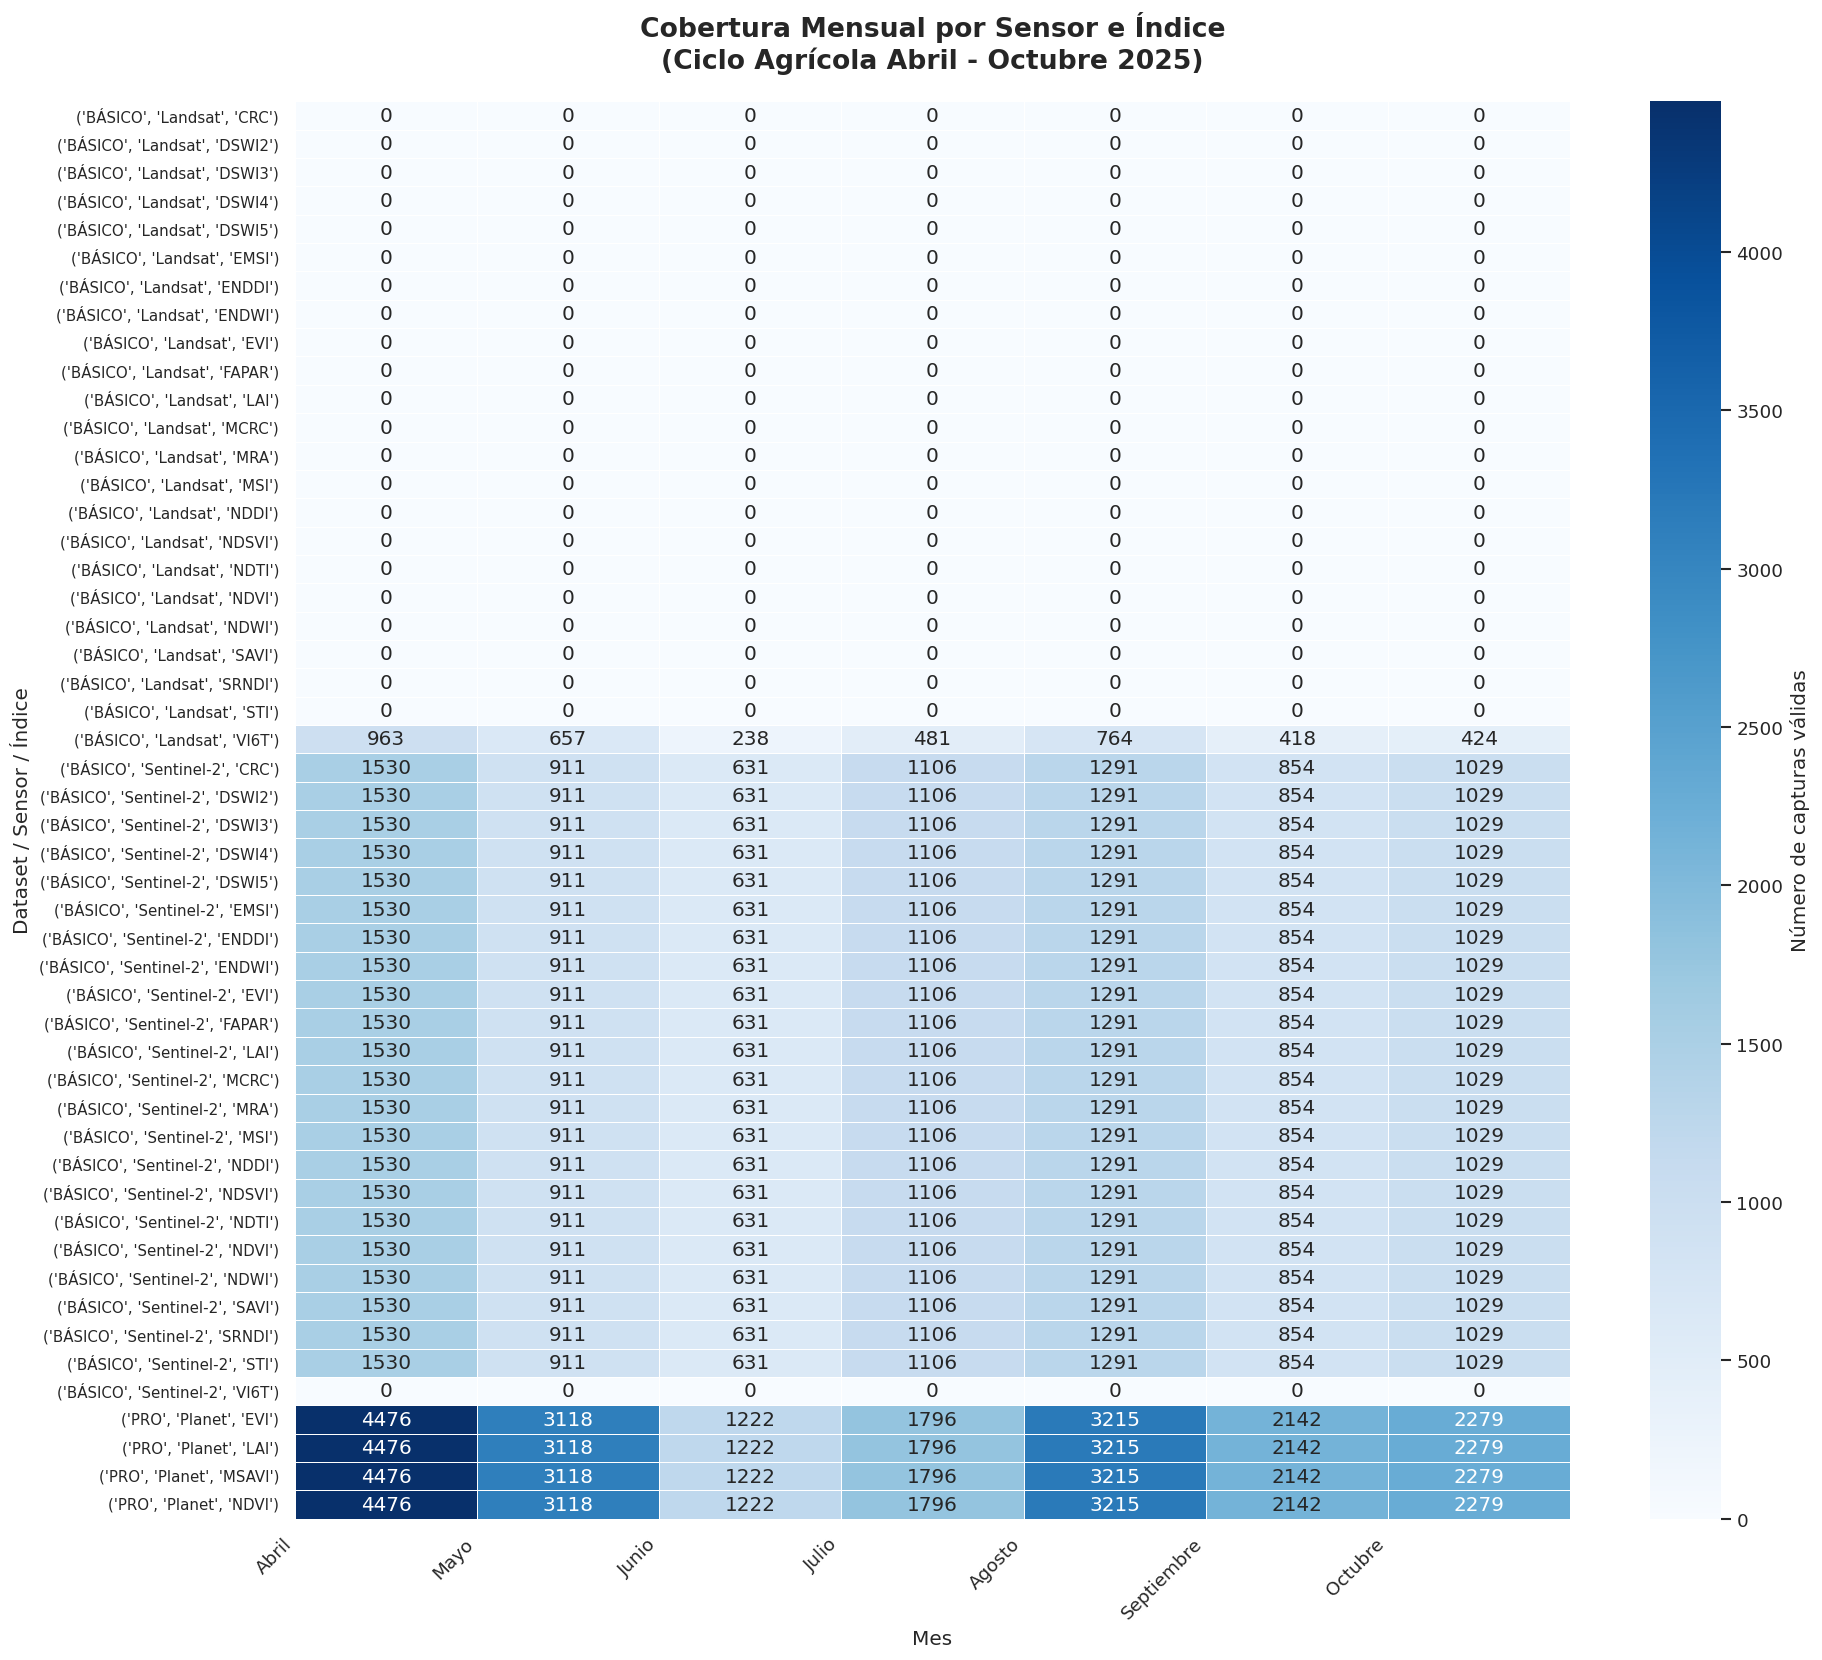


✅ Gráfico guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/01_calidad/01_mapa_cobertura_mensual.png

📊 RESUMEN DE COBERTURA:

   BÁSICO / Landsat:
   • Índices disponibles: 23
   • Total de capturas válidas: 3,945
      Abril: 963 capturas
      Mayo: 657 capturas
      Junio: 238 capturas
      Julio: 481 capturas
      Agosto: 764 capturas
      Septiembre: 418 capturas
      Octubre: 424 capturas

   BÁSICO / Sentinel-2:
   • Índices disponibles: 23
   • Total de capturas válidas: 161,744
      Abril: 33,660 capturas
      Mayo: 20,042 capturas
      Junio: 13,882 capturas
      Julio: 24,332 capturas
      Agosto: 28,402 capturas
      Septiembre: 18,788 capturas
      Octubre: 22,638 capturas

   PRO / Planet:
   • Índices disponibles: 4
   • Total de capturas válidas: 72,992
      Abril: 17,904 capturas
      Mayo: 12,472 capturas
      Junio: 4,888 capturas
      Julio: 7,184 capturas
      Agosto: 12,860 capturas
      Septiembre: 8,568 capturas
      Octubre: 9,116 

In [ ]:
# ============================================================
# 8. GRÁFICO ESTELAR: MAPA DE CALOR DE COBERTURA MENSUAL
# ============================================================
# Este gráfico demuestra por qué ciertos meses críticos de la fenología
# de la cebada requieren fusión de satélites

print("=" * 60)
print("MAPA DE CALOR DE COBERTURA MENSUAL POR SENSOR E ÍNDICE")
print("=" * 60)

# Preparar la matriz de cobertura: (sensor + índice) x (mes)
# Para cada combinación, contar cuántas capturas válidas hay por mes

def calcular_cobertura_mensual(df, columna_sensor=True):
    """Calcula la cobertura mensual agrupando por sensor e índice"""
    # Identificar las columnas de índices
    sufijos = ['_promedio', '_std', '_min', '_max']
    columnas_base = []
    for col in df.columns:
        for suf in sufijos:
            if suf in col:
                base = col.replace(suf, '')
                if base not in columnas_base and base != 'porcentaje_nubosidad':
                    columnas_base.append(base)
                break

    resultados = []
    for sensor in df['sensor'].unique():
        g = df[df['sensor'] == sensor]
        for indice in columnas_base:
            col_prom = f'{indice}_promedio'
            if col_prom in g.columns:
                # Contar capturas con valor no nulo por mes
                capturas_mes = g.groupby('mes')[col_prom].apply(
                    lambda x: x.notna().sum()
                )
                for mes in MESES:
                    n_capturas = capturas_mes.get(mes, 0)
                    resultados.append({
                        'sensor': sensor,
                        'indice': indice.upper(),
                        'mes': mes,
                        'n_capturas': n_capturas
                    })

    return pd.DataFrame(resultados)

# Calcular para ambos datasets
cobertura_basico = calcular_cobertura_mensual(df_basico_ventana)
cobertura_pro = calcular_cobertura_mensual(df_pro_ventana)

# Combinar ambos datasets
cobertura_basico['dataset'] = 'BÁSICO'
cobertura_pro['dataset'] = 'PRO'
cobertura_combinada = pd.concat([cobertura_basico, cobertura_pro], ignore_index=True)

# Crear la matriz pivote para el heatmap
# Filas: dataset + sensor + índice, Columnas: meses
matriz_cobertura = cobertura_combinada.pivot_table(
    values='n_capturas',
    index=['dataset', 'sensor', 'indice'],
    columns='mes',
    aggfunc='sum',
    fill_value=0
)

# Reordenar columnas por los meses del ciclo
matriz_cobertura = matriz_cobertura.reindex(columns=MESES)

# Crear etiquetas más cortas para los meses
etiquetas_meses = [f'{m}' for m in NOMBRES_MESES]

# Graficar el heatmap
fig, ax = plt.subplots(figsize=(16, 14))

# Usar un colormap secuencial
sns.heatmap(
    matriz_cobertura,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Número de capturas válidas'},
    ax=ax
)

ax.set_xticks(range(len(etiquetas_meses)))
ax.set_xticklabels(etiquetas_meses, rotation=45, ha='right')
ax.set_yticklabels([f'{idx}' for idx in matriz_cobertura.index], rotation=0, fontsize=9)
ax.set_title('Cobertura Mensual por Sensor e Índice\n(Ciclo Agrícola Abril - Octubre 2025)', fontsize=16, pad=20)
ax.set_xlabel('Mes', fontsize=12)
ax.set_ylabel('Dataset / Sensor / Índice', fontsize=12)

plt.tight_layout()
plt.savefig(SALIDA / '01_mapa_cobertura_mensual.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"\n✅ Gráfico guardado: {SALIDA / '01_mapa_cobertura_mensual.png'}")

# Estadísticas de cobertura
print("\n📊 RESUMEN DE COBERTURA:")
for (dataset, sensor), grupo in cobertura_combinada.groupby(['dataset', 'sensor']):
    indices = grupo['indice'].unique()
    total_capturas = grupo['n_capturas'].sum()
    print(f"\n   {dataset} / {sensor}:")
    print(f"   • Índices disponibles: {len(indices)}")
    print(f"   • Total de capturas válidas: {total_capturas:,}")
    # Capturas por mes
    por_mes = grupo.groupby('mes')['n_capturas'].sum()
    for mes in MESES:
        n = por_mes.get(mes, 0)
        mes_nombre = NOMBRES_MESES[MESES.index(mes)]
        print(f"      {mes_nombre}: {n:,} capturas")

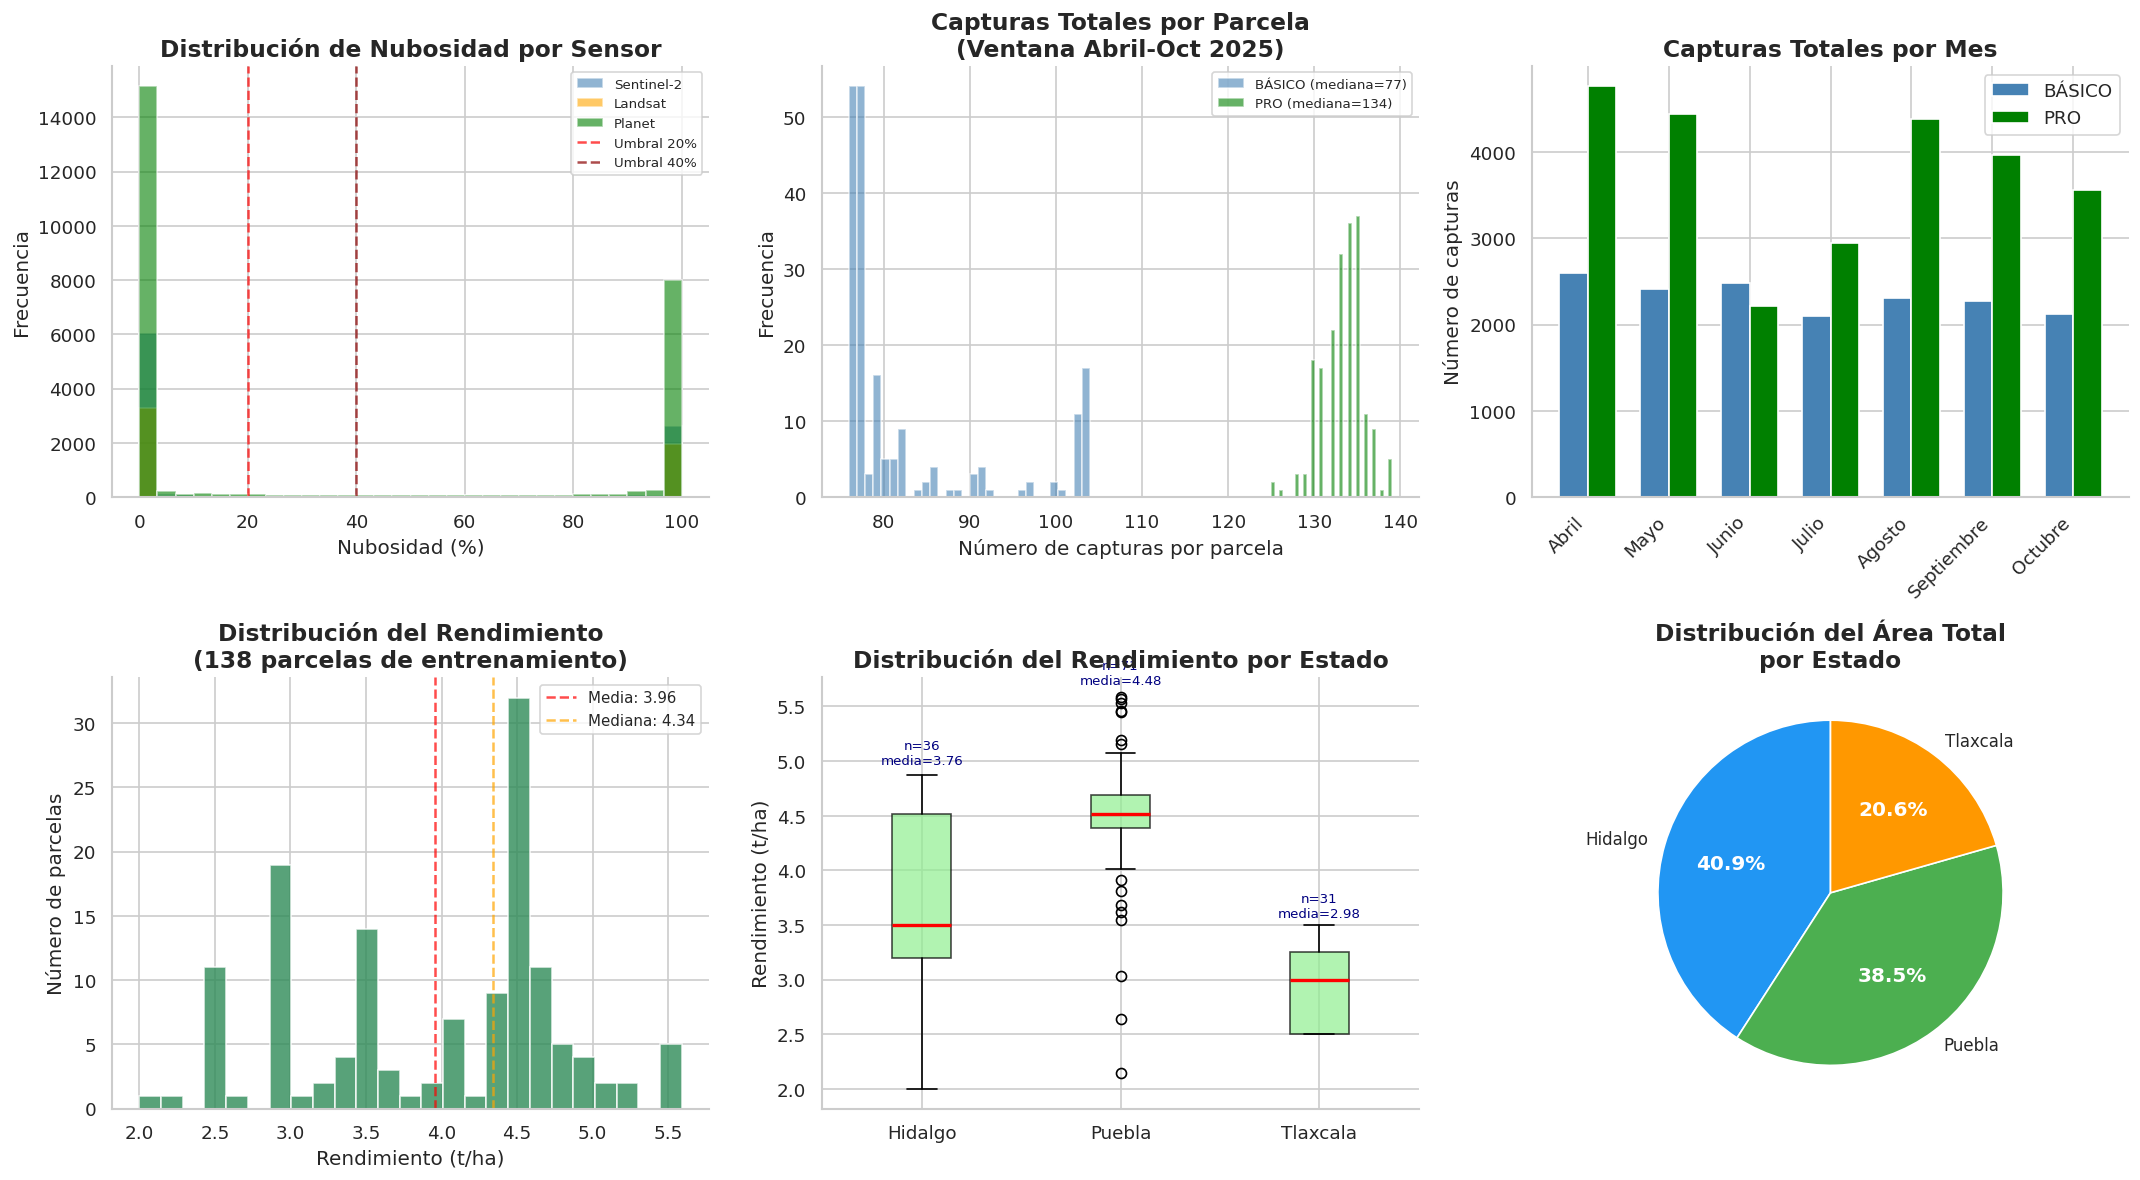


✅ Gráfico guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/01_calidad/02_diagnosticos_calidad.png


In [ ]:
# ============================================================
# 9. GRÁFICOS COMPLEMENTARIOS DE DIAGNÓSTICO
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# --- Gráfico 1: Distribución de nubosidad ---
ax = axes[0, 0]
nubes_s2 = df_basico_ventana[df_basico_ventana['sensor'] == 'Sentinel-2']['porcentaje_nubosidad'].dropna()
nubes_l8 = df_basico_ventana[df_basico_ventana['sensor'] == 'Landsat']['porcentaje_nubosidad'].dropna()
nubes_planet = df_pro_ventana['porcentaje_nubosidad'].dropna()

ax.hist(nubes_s2, bins=30, alpha=0.6, label='Sentinel-2', color='steelblue')
ax.hist(nubes_l8, bins=30, alpha=0.6, label='Landsat', color='orange')
ax.hist(nubes_planet, bins=30, alpha=0.6, label='Planet', color='green')
ax.axvline(20, color='red', linestyle='--', alpha=0.7, label='Umbral 20%')
ax.axvline(40, color='darkred', linestyle='--', alpha=0.7, label='Umbral 40%')
ax.set_xlabel('Nubosidad (%)')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución de Nubosidad por Sensor')
ax.legend(fontsize=8)

# --- Gráfico 2: Capturas por parcela ---
ax = axes[0, 1]
capturas_basico = df_basico_ventana.groupby('ID_POLIGONO').size()
capturas_pro = df_pro_ventana.groupby('ID_POLIGONO').size()

ax.hist(capturas_basico, bins=30, alpha=0.6, label=f'BÁSICO (mediana={capturas_basico.median():.0f})', color='steelblue')
ax.hist(capturas_pro, bins=30, alpha=0.6, label=f'PRO (mediana={capturas_pro.median():.0f})', color='green')
ax.set_xlabel('Número de capturas por parcela')
ax.set_ylabel('Frecuencia')
ax.set_title('Capturas Totales por Parcela\n(Ventana Abril-Oct 2025)')
ax.legend(fontsize=8)

# --- Gráfico 3: Capturas por mes ---
ax = axes[0, 2]
meses_basico = df_basico_ventana.groupby('mes').size()
meses_pro = df_pro_ventana.groupby('mes').size()

x = np.arange(len(MESES))
width = 0.35
ax.bar(x - width/2, [meses_basico.get(m, 0) for m in MESES], width, label='BÁSICO', color='steelblue')
ax.bar(x + width/2, [meses_pro.get(m, 0) for m in MESES], width, label='PRO', color='green')
ax.set_xticks(x)
ax.set_xticklabels(NOMBRES_MESES, rotation=45, ha='right')
ax.set_ylabel('Número de capturas')
ax.set_title('Capturas Totales por Mes')
ax.legend()

# --- Gráfico 4: Distribución de rendimiento ---
ax = axes[1, 0]
rendimiento = df_entrenamiento['RENDIMIENTO_T_HA'].dropna()
ax.hist(rendimiento, bins=25, edgecolor='white', color='seagreen', alpha=0.8)
ax.axvline(rendimiento.mean(), color='red', linestyle='--', alpha=0.7, label=f'Media: {rendimiento.mean():.2f}')
ax.axvline(rendimiento.median(), color='orange', linestyle='--', alpha=0.7, label=f'Mediana: {rendimiento.median():.2f}')
ax.set_xlabel('Rendimiento (t/ha)')
ax.set_ylabel('Número de parcelas')
ax.set_title('Distribución del Rendimiento\n(138 parcelas de entrenamiento)')
ax.legend(fontsize=9)

# --- Gráfico 5: Rendimiento por estado ---
ax = axes[1, 1]
rendimiento_estado = df_geo[df_geo['CONJUNTO'] == 'ENTRENAMIENTO'].groupby('Estado')['RENDIMIENTO_T_HA']
estados_presentes = [e for e in rendimiento_estado.groups.keys() if e is not None]
data_box = [rendimiento_estado.get_group(e).dropna() for e in estados_presentes]

bp = ax.boxplot(data_box, labels=estados_presentes, patch_artist=True,
                boxprops=dict(facecolor='lightgreen', alpha=0.7),
                medianprops=dict(color='red', linewidth=2))
ax.set_ylabel('Rendimiento (t/ha)')
ax.set_title('Distribución del Rendimiento por Estado')

# Agregar estadísticas
for i, estado in enumerate(estados_presentes):
    datos = rendimiento_estado.get_group(estado).dropna()
    ax.text(i + 1, datos.max() * 1.02, f'n={len(datos)}\nmedia={datos.mean():.2f}',
            ha='center', fontsize=8, color='navy')

# --- Gráfico 6: Área de parcelas por estado ---
ax = axes[1, 2]
area_estado = df_geo.groupby('Estado')['AREA_HA'].apply(lambda x: x.sum() if x.notna().any() else 0)
colores = ['#2196F3', '#4CAF50', '#FF9800']
wedges, texts, autotexts = ax.pie(area_estado.values, labels=area_estado.index, autopct='%1.1f%%',
                                   colors=colores, startangle=90)
for text in texts:
    text.set_fontsize(10)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
ax.set_title('Distribución del Área Total\npor Estado')

plt.tight_layout()
plt.savefig(SALIDA / '02_diagnosticos_calidad.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"\n✅ Gráfico guardado: {SALIDA / '02_diagnosticos_calidad.png'}")

In [ ]:
# ============================================================
# HALLAZGOS CALCULADOS (reemplazan los marcadores XXX de la versión anterior)
# Las cifras que se citen en el reporte deben salir de esta celda / del JSON, no de texto escrito a mano.
# ============================================================
hallazgos = {}

# 1. Estructura del dataset
hallazgos['parcelas'] = {
    'total': int(len(df_maestro)),
    'entrenamiento': int(len(df_entrenamiento)),
    'prediccion': int(len(df_prediccion)),
    'por_estado': {k: int(v) for k, v in df_geo.groupby('Estado').size().items()},
    'area_total_ha': round(float(df_maestro['AREA_HA'].sum()), 2),
    'area_mediana_ha': round(float(df_maestro['AREA_HA'].median()), 2),
    'area_min_ha': round(float(df_maestro['AREA_HA'].min()), 2),
    'area_max_ha': round(float(df_maestro['AREA_HA'].max()), 2),
}

# 2. Cobertura mensual: parcelas con al menos una captura, por sensor y mes (ventana abril-octubre)
def cobertura_parcelas(df):
    return df.groupby(['sensor', 'mes'])['ID_POLIGONO'].nunique().unstack(fill_value=0)

cob_basico = cobertura_parcelas(df_basico_ventana)
cob_pro = cobertura_parcelas(df_pro_ventana)
print("Parcelas con >=1 captura por sensor y mes (BÁSICO):")
print(cob_basico.to_string())
print("\nParcelas con >=1 captura por mes (PRO):")
print(cob_pro.to_string())

hallazgos['cobertura_parcelas_por_mes'] = {
    'basico': {s: {m: int(v) for m, v in fila.items()} for s, fila in cob_basico.iterrows()},
    'pro': {s: {m: int(v) for m, v in fila.items()} for s, fila in cob_pro.iterrows()},
}
for nombre, cob in [('BÁSICO', cob_basico), ('PRO', cob_pro)]:
    for sensor, fila in cob.iterrows():
        print(f"   {nombre}/{sensor}: mes con menor cobertura = {fila.idxmin()} ({int(fila.min())} parcelas)")

# 3. Nubosidad (indicador de calidad cuyo método no está documentado; NaN no significa cielo despejado)
def resumen_nubes(df):
    s = df['porcentaje_nubosidad']
    return {'media': round(float(s.mean()), 1), 'mediana': round(float(s.median()), 1),
            'pct_desconocida': round(float(s.isna().mean() * 100), 1),
            'pct_menor_igual_20': round(float((s <= 20).mean() * 100), 1)}

hallazgos['nubosidad'] = {'basico': resumen_nubes(df_basico_ventana), 'pro': resumen_nubes(df_pro_ventana)}
print("\nNubosidad:", hallazgos['nubosidad'])

# 4. Valores faltantes e inconsistencias (calculados en la celda de diagnóstico)
hallazgos['faltantes_top5'] = {
    'basico': {k: round(float(v) * 100, 1) for k, v in faltantes_basico.head(5).items()},
    'pro': {k: round(float(v) * 100, 1) for k, v in faltantes_pro.head(5).items()},
}
hallazgos['inconsistencias_min_prom_max'] = int(inconsistencias)

with open(SALIDA / 'hallazgos_libreta01.json', 'w', encoding='utf-8') as f:
    json.dump(hallazgos, f, indent=2, ensure_ascii=False)
print(f"\n✅ Guardado: {SALIDA / 'hallazgos_libreta01.json'}")

Parcelas con >=1 captura por sensor y mes (BÁSICO):
mes         2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10
sensor                                                                   
Landsat         197      197      197      197      197      197      197
Sentinel-2      197      197      197      197      197      197      197

Parcelas con >=1 captura por mes (PRO):
mes     2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10
sensor                                                               
Planet      197      197      197      197      197      197      197
   BÁSICO/Landsat: mes con menor cobertura = 2025-04 (197 parcelas)
   BÁSICO/Sentinel-2: mes con menor cobertura = 2025-04 (197 parcelas)
   PRO/Planet: mes con menor cobertura = 2025-04 (197 parcelas)

Nubosidad: {'basico': {'media': 34.8, 'mediana': 0.0, 'pct_desconocida': 2.7, 'pct_menor_igual_20': 60.5}, 'pro': {'media': 36.6, 'mediana': 0.0, 'pct_desconocida': 0.0, 'pct_menor_igual_20': 60.4}

## Conclusiones de la Libreta 01

Las cifras de esta libreta se **calculan en la celda anterior** y se guardan en `hallazgos_libreta01.json`. Esas son las que deben citarse en el reporte; no se escriben a mano.

### Qué sí se puede afirmar con esta libreta
- **Estructura:** 197 parcelas georreferenciadas, 138 con rendimiento conocido y 59 sin él (ver tabla por estado y municipio).
- **Cobertura:** la cantidad de parcelas con observación cambia por mes y por sensor (tablas de la celda anterior); los meses con menor cobertura se identifican en esa misma salida.
- **Calidad:** `porcentaje_nubosidad` es un indicador de calidad cuyo método no está documentado; un valor desconocido no equivale a cielo despejado, y los vacíos de índices no se pueden atribuir automáticamente a nubes.

### Qué NO se puede afirmar con esta libreta
- Que la fusión de sensores *mejore* la predicción: aquí solo se documenta la cobertura; no se probó el efecto sobre el modelo.
- Que los meses de baja cobertura coincidan con etapas fenológicas concretas: el dataset no trae fechas de siembra ni de cosecha.
- Que las inconsistencias detectadas sean errores: se marcan, no se eliminan.

### Siguiente paso (Libreta 02)
- Extraer clima (CHIRPS, CHIRTS) y topografía (INEGI) por parcela y **verificar** que las 21 variables climáticas de abril a octubre entran a la matriz.
- Construir bloques temáticos y métricas fenológicas (AUC, delta máximo, P90, IQR, mes del máximo).

In [ ]:
# ============================================================
# 10. EXPORTACIÓN DE ARTEFACTOS DE LA LIBRETA 01
# ============================================================

# Guardar un resumen de la libreta como JSON
resumen_libreta01 = {
    'version': '1.0-calidad-contexto',
    'ventana_temporal': {'inicio': INICIO, 'fin': FIN},
    'n_parcelas': int(len(df_maestro)),
    'n_entrenamiento': int(len(df_entrenamiento)),
    'n_prediccion': int(len(df_prediccion)),
    'distribucion_estado': df_geo.groupby('Estado').size().to_dict(),
    'area_total_ha': float(df_maestro['AREA_HA'].sum()),
    'capturas_ventana': {
        'basico_sentinel2': int(len(df_basico_ventana[df_basico_ventana['sensor'] == 'Sentinel-2'])),
        'basico_landsat': int(len(df_basico_ventana[df_basico_ventana['sensor'] == 'Landsat'])),
        'pro_planet': int(len(df_pro_ventana))
    },
    'nubosidad_media': {
        'basico': float(df_basico_ventana['porcentaje_nubosidad'].mean()) if 'porcentaje_nubosidad' in df_basico_ventana.columns else None,
        'pro': float(df_pro_ventana['porcentaje_nubosidad'].mean()) if 'porcentaje_nubosidad' in df_pro_ventana.columns else None
    },
    'rendimiento': {
        'media': float(df_entrenamiento['RENDIMIENTO_T_HA'].mean()),
        'mediana': float(df_entrenamiento['RENDIMIENTO_T_HA'].median()),
        'desviacion': float(df_entrenamiento['RENDIMIENTO_T_HA'].std())
    },
    'archivos_generados': [
        '01_mapa_cobertura_mensual.png',
        '02_diagnosticos_calidad.png',
        'resumen_libreta01.json'
    ]
}

with open(SALIDA / 'resumen_libreta01.json', 'w') as f:
    json.dump(resumen_libreta01, f, indent=2, ensure_ascii=False)

# Listar todos los archivos generados
print("=" * 60)
print("ARCHIVOS GENERADOS EN ESTA LIBRETA")
print("=" * 60)
for archivo in sorted(SALIDA.iterdir()):
    tamaño = archivo.stat().st_size
    if tamaño > 1024 * 1024:
        tamaño_str = f"{tamaño / (1024*1024):.1f} MB"
    elif tamaño > 1024:
        tamaño_str = f"{tamaño / 1024:.1f} KB"
    else:
        tamaño_str = f"{tamaño} B"
    print(f"   • {archivo.name} ({tamaño_str})")

print("\n" + "=" * 60)
print("LIBRETA 01 COMPLETADA")
print("=" * 60)
print("\nArtefactos clave para el reporte:")
print("   1. 01_mapa_cobertura_mensual.png → Sección: Introducción/Justificación")
print("   2. 02_diagnosticos_calidad.png → Sección: Introducción")
print("   3. resumen_libreta01.json → Datos numéricos para el texto")
print("\n Siguiente paso: Ejecutar la Libreta 02 - Ingeniería Fenológica y Espacial")

ARCHIVOS GENERADOS EN ESTA LIBRETA
   • 01_mapa_cobertura_mensual.png (884.0 KB)
   • 02_diagnosticos_calidad.png (384.6 KB)
   • hallazgos_libreta01.json (1.6 KB)
   • resumen_libreta01.json (764 B)

LIBRETA 01 COMPLETADA

Artefactos clave para el reporte:
   1. 01_mapa_cobertura_mensual.png → Sección: Introducción/Justificación
   2. 02_diagnosticos_calidad.png → Sección: Introducción
   3. resumen_libreta01.json → Datos numéricos para el texto

 Siguiente paso: Ejecutar la Libreta 02 - Ingeniería Fenológica y Espacial
